# 01 — Data Prep

Going through the data step by step (basically the milestone questions in order): what's in it, what's missing, cleaning, distributions, getting it ready for models, and a first look with SVD / t-SNE.

Nothing to upload on the user end —- the Hugging Face table downloads itself, and the 2 Zenodo CSVs are already in `data/zenodo/`.

## Setup

In [ ]:
!mkdir -p data/raw data/clean

!wget -q "https://huggingface.co/datasets/ninar12/aesthetics-wiki/resolve/main/data/train-00000-of-00001.parquet" -O data/raw/aesthetics_wiki.parquet

!wget -q "https://github.com/PSAM-5020-2026F-A/5020-utils/raw/main/src/text_utils.py" -O text_utils.py

!ls -la data/raw data/zenodo

data/raw:
total 4580
drwxrwxrwx+ 2 codespace codespace    4096 Nov 25 03:42 .
drwxrwxrwx+ 5 codespace codespace    4096 Nov 25 03:42 ..
-rw-rw-rw-  1 codespace codespace 4678728 Nov 25 03:42 aesthetics_wiki.parquet

data/zenodo:
total 2864
drwxrwxrwx+ 2 codespace codespace    4096 Nov 25 03:41 .
drwxrwxrwx+ 5 codespace codespace    4096 Nov 25 03:42 ..
-rw-rw-rw-  1 codespace codespace     631 Nov 25 03:41 README.md
-rw-rw-rw-  1 codespace codespace 1974407 Nov 25 03:41 wiki_ecosystem.csv
-rw-rw-rw-  1 codespace codespace  939459 Nov 25 03:41 wiki_ecosystem_edges.csv


In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.manifold import TSNE
from sklearn.model_selection import train_test_split

from text_utils import get_top_words

---
# 1. What's the data?

| file | where it's from | format |
|---|---|---|
| `data/raw/aesthetics_wiki.parquet` | Hugging Face (downloaded above) | parquet → **main table** |
| `data/zenodo/wiki_ecosystem.csv` | Zenodo (in the repo) | CSV → using it to fill missing decades |
| `data/zenodo/wiki_ecosystem_edges.csv` | Zenodo (in the repo) | CSV → the wiki's "related aesthetic" links |

In [ ]:
hf_df = pd.read_parquet("data/raw/aesthetics_wiki.parquet")
zen_df = pd.read_csv("data/zenodo/wiki_ecosystem.csv")
edges_df = pd.read_csv("data/zenodo/wiki_ecosystem_edges.csv")

print("Hugging Face:", hf_df.shape)
print("Zenodo aesthetics:", zen_df.shape)
print("Zenodo links:", edges_df.shape)

Hugging Face: (1022, 13)
Zenodo aesthetics: (1128, 7)
Zenodo links: (20925, 2)


Column types (`object` = text or lists):

In [ ]:
hf_df.dtypes

title                    str
description              str
keywords_spacy        object
alt_titles            object
overview                 str
related_aesthetics    object
related_media         object
extract_decade           str
key_motifs            object
related_brands        object
key_values            object
key_colours           object
fashion_sentences        str
dtype: object

Everything in one row. using Vaporwave for this example

In [ ]:
vaporwave = hf_df[hf_df["title"] == "Vaporwave"].iloc[0]

for col in hf_df.columns:
  print(col, ":", str(vaporwave[col])[:200])
  print()

title : Vaporwave

description : Vaporwave






Other names
Slushwave, Vapor


Decade of origin
2010s


Creator/s
James Ferraro, Daniel Lopatin, Ramona Xavier, Devon Hendryx


Key motifs
Drug use and distorted/dream-like imagery, Ja

keywords_spacy : ['mind' '95' 'heavy' ... 'zone' 'shipped' 'elements']

alt_titles : ['Slushwave' 'Vapor']

overview : Despite the lack of clarity in the 'Viberian' and 'Viberian' styles, the 'Viberian' and 'Viberian' aesthetics.

related_aesthetics : ['2010' 'Internet' 'Avant' 'Basic' 'Balearic' 'Beat' 'Barber' 'Salon'
 'Cassette' 'Futurism' 'City' 'Pop' 'Cleancore' 'Cyberdelic' 'Cyberpunk'
 'Doomer' 'Dopamine' 'Dreamwave' 'Drugcore' 'Emo' 'Rap' '

related_media : None

extract_decade : 2010s

key_motifs : ['Drug use and distorted/dream-like imagery' 'Japanese language'
 'culture and media' 'antiquated 3D graphics and retro technology'
 'Hellenic statues and pillars' 'dolphins' 'beaches and exotic folia

related_brands : ['Agora Road' 'Vapor95' 'Palm Tre

**What's in it**

- 1,022 aesthetics, 13 columns. One row = one aesthetic from the Aesthetics Wiki.
- Short text: title, decade, overview (a 20–80 word summary).
- Lists: motifs, colours, values, brands, media, other names.
- Long text: description = the whole article (starts with the infobox pasted in).
- Zenodo adds a messier decade column for 1,128 aesthetics + 20,925 "related" links.



---
# 2. Features vs. outcomes

| what | columns | role |
|---|---|---|
| tags | motifs + colours + values | features (text → numbers) |
| language | overview / description | features (text → numbers) |
| time | decade → era | outcome to predict, or just a color label for plots |
| links | Zenodo edges | not a feature — using them to check if the map makes sense |

So it's mostly features only → unsupervised stuff (clustering, SVD, t-SNE). Era / decade is the one thing I can try to predict.

---
# 3. Missing data

`notna()` counts an empty list `[]` as filled, so counting by hand: missing = `None`, `nan`, `[]` or empty text.

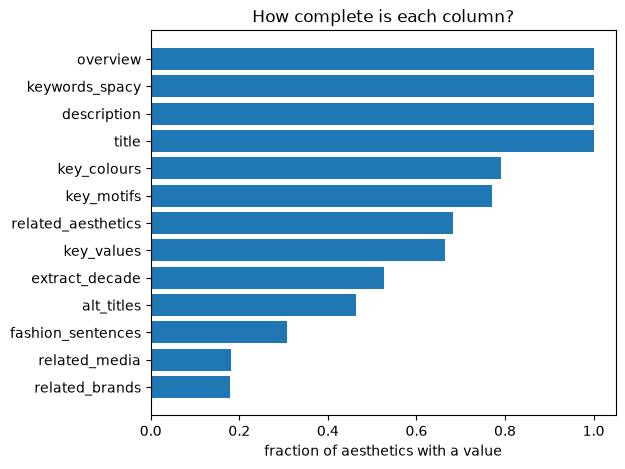

related_brands        0.18
related_media         0.18
fashion_sentences     0.31
alt_titles            0.46
extract_decade        0.53
key_values            0.66
related_aesthetics    0.68
key_motifs            0.77
key_colours           0.79
title                 1.00
description           1.00
keywords_spacy        1.00
overview              1.00
dtype: float64

In [ ]:
filled = {}

for col in hf_df.columns:
  count = 0
  for v in hf_df[col]:
    if str(v) not in ["None", "nan", "[]", ""]:
      count += 1
  filled[col] = count / len(hf_df)

filled = pd.Series(filled).sort_values()

plt.figure(figsize=(6, 5))
plt.barh(filled.index, filled.values)
plt.xlabel("fraction of aesthetics with a value")
plt.title("How complete is each column?")
plt.show()

filled.round(2)

Not missing but broken--> `related_aesthetics` got split into word pieces.

In [ ]:
print(vaporwave["related_aesthetics"])

['2010' 'Internet' 'Avant' 'Basic' 'Balearic' 'Beat' 'Barber' 'Salon'
 'Cassette' 'Futurism' 'City' 'Pop' 'Cleancore' 'Cyberdelic' 'Cyberpunk'
 'Doomer' 'Dopamine' 'Dreamwave' 'Drugcore' 'Emo' 'Rap' 'Frasurbane'
 'Frutiger' 'Aero' 'Future' 'Funk' 'Glitch' 'Art' 'Glowwave' 'Grime' 'Art'
 'Hardvapor' 'Hauntology' 'Hellenic' 'Holosexual' 'Icepunk' 'Internet'
 'Awesomesauce' 'Liminal' 'Space' 'Lo-' 'Fi' 'Lounge' 'Mallsoft' 'Memphis'
 'Design' 'Neoclassical' 'Po' 'Mo' 'Neo-' 'Pop' 'Nerdcore' 'Techno'
 'Neubrutalism' 'New' 'Age' 'New' 'Romantic' 'New' 'Wave' 'Nostalgiacore'
 'Pastel' 'Grunge' 'Politicalwave' 'Seapunk' 'Signalwave' 'Silicon'
 'Dreams' 'Slimepunk' 'Surreal' 'Memer' 'Synthwave' 'Trillwave' 'Trxsh'
 'Visual' 'Pollution' 'Weathercore' 'Webcore' 'Weirdcore' 'Witch' 'House'
 'Y2' 'Futurism']


**What I'm doing about it:**

| problem | fix |
|---|---|
| decade missing for about half (Dreamcore, Frutiger Aero…) | fill from Zenodo's decade text, otherwise era = "unknown" |
| some aesthetics have no motifs / colours / values | empty text; the ones with no tags at all just get skipped in the tag stuff |
| overview | never missing, so it's the main text |
| related_aesthetics broken | using the Zenodo links instead |
| brands / media mostly empty | not using them for now |

---
# 4. Cleaning

### Tag lists → text

Joining each list into one lowercase string. `tags_text` = motifs + colours + values together (what the vectorizer reads).

In [ ]:
motifs_text = []
colours_text = []
values_text = []
tags_text = []

for i in range(len(hf_df)):
  row = hf_df.iloc[i]

  m = ""
  c = ""
  v = ""
  if row["key_motifs"] is not None:
    m = ", ".join(list(row["key_motifs"])).lower()
  if row["key_colours"] is not None:
    c = ", ".join(list(row["key_colours"])).lower()
  if row["key_values"] is not None:
    v = ", ".join(list(row["key_values"])).lower()

  motifs_text.append(m)
  colours_text.append(c)
  values_text.append(v)
  tags_text.append((m + " " + c + " " + v).replace(",", " ").strip())

hf_df["motifs"] = motifs_text
hf_df["colours"] = colours_text
hf_df["values"] = values_text
hf_df["tags_text"] = tags_text

display(hf_df[["title", "motifs", "colours", "values"]].head())

,title,motifs,colours,values
0,Mallsoft,"shopping malls (empty and full), mall food, ma...","pink, teal, mint green, purple, black, white, ...","shop till you drop, exploration"
1,Femme Fatale,"mystery, intelligence, beauty, seduction, power","red, black, dark green, dark blue, metallic tones","enticement, scheming, heartlessness, lust"
2,Indicolite,"diamonds, water, clouds, vintage statues","blue, indigo, cyan, white, grey",
3,Kingcore,"control, leadership, war, crowns, royal lifest...","gold, royal blue, black, white, purple, red","power, money, hedonism, conquest, status, duty..."
4,Onii Kei,,,


### Decades

`"2010s"` → `2010`. If it's missing, grab the first word that looks like `"1990s"` from the Zenodo text.

In [ ]:
zen_decade_text = {}
for name, text in zip(zen_df["aesthetic"], zen_df["decade_of_origin"]):
  if not pd.isna(text):
    zen_decade_text[name] = text

decades = []
sources = []

for name, d in zip(hf_df["title"], hf_df["extract_decade"]):
  decade = None
  source = "none"

  if not pd.isna(d):
    decade = int(d[:4])
    source = "hugging face"

  elif name in zen_decade_text:
    text = zen_decade_text[name].replace("-", " ").replace(",", " ")
    for w in text.split():
      # a word like "1990s": 5 characters, 4 digits + "s"
      if decade is None and len(w) == 5 and w[:4].isdigit() and w[4] == "s":
        decade = int(w[:4])
        source = "zenodo"

  decades.append(decade)
  sources.append(source)

hf_df["decade"] = decades
hf_df["decade_source"] = sources

hf_df["decade_source"].value_counts()

decade_source
hugging face    538
none            327
zenodo          157
Name: count, dtype: int64

### Eras

Cut-offs: before 1990 = pre-internet, 90s = Old Web, 2000s = Web 2.0, 2010s = Tumblr, 2020s = TikTok.

In [ ]:
eras = []

for d in hf_df["decade"]:
  if pd.isna(d):
    eras.append("unknown")
  elif d < 1990:
    eras.append("pre-internet")
  elif d < 2000:
    eras.append("Old Web")
  elif d < 2010:
    eras.append("Web 2.0")
  elif d < 2020:
    eras.append("Tumblr")
  else:
    eras.append("TikTok")

hf_df["era"] = eras

era_order = ["pre-internet", "Old Web", "Web 2.0", "Tumblr", "TikTok", "unknown"]
hf_df["era"].value_counts()[era_order]

era
pre-internet    283
Old Web          82
Web 2.0         101
Tumblr          148
TikTok           81
unknown         327
Name: count, dtype: int64

### Counts per aesthetic

In [ ]:
n_tags = []
overview_words = []

for i in range(len(hf_df)):
  count = 0
  for col in ["motifs", "colours", "values"]:
    for t in hf_df[col][i].split(","):
      if t.strip() != "":
        count += 1
  n_tags.append(count)
  overview_words.append(len(hf_df["overview"][i].split()))

hf_df["n_tags"] = n_tags
hf_df["overview_words"] = overview_words

print("aesthetics with no tags at all:", (hf_df["n_tags"] == 0).sum())

aesthetics with no tags at all: 79


---
# 5. Distributions

### Numbers

Tags per aesthetic, overview length, decade → these have a mean / median (in the plot titles).

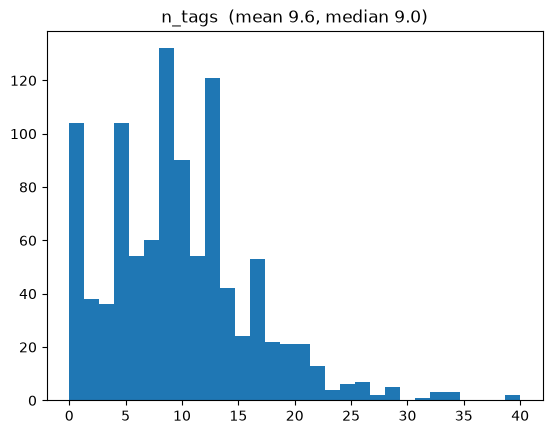

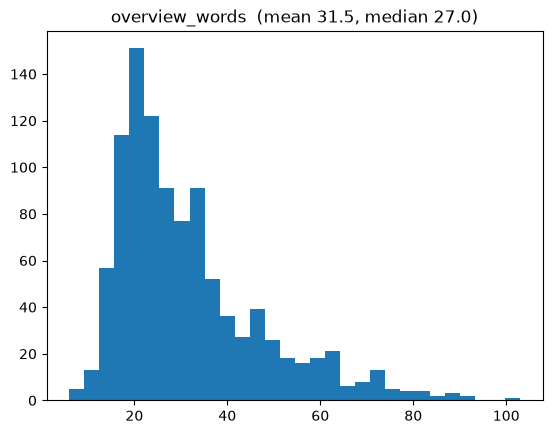

,n_tags,overview_words,decade
count,1022.0,1022.0,695.0
mean,9.6,31.5,1975.6
std,6.4,15.6,66.2
min,0.0,6.0,1000.0
25%,5.0,20.0,1970.0
50%,9.0,27.0,1990.0
75%,13.0,38.0,2010.0
max,40.0,103.0,2020.0


In [ ]:
for col in ["n_tags", "overview_words"]:
  plt.hist(hf_df[col], bins=30)
  plt.title(col + "  (mean " + str(round(hf_df[col].mean(), 1)) + ", median " + str(hf_df[col].median()) + ")")
  plt.show()

hf_df[["n_tags", "overview_words", "decade"]].describe().round(1)

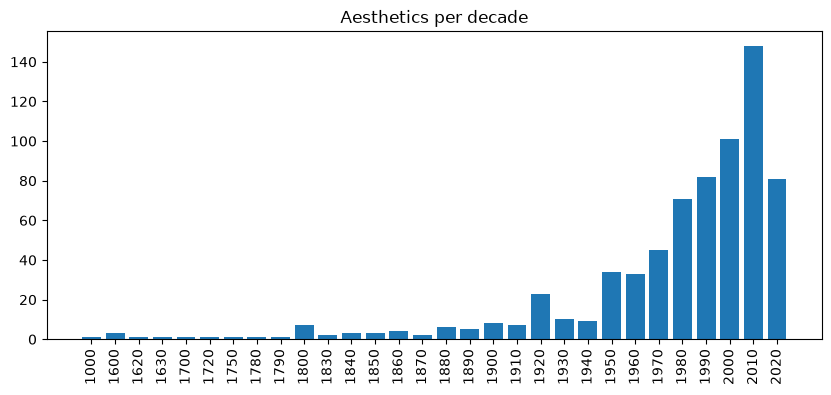

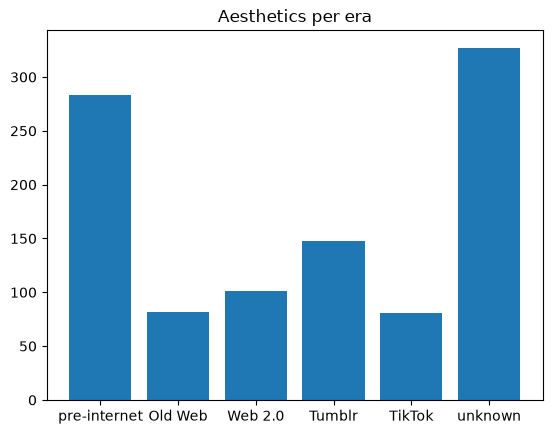

In [ ]:
decade_counts = hf_df["decade"].value_counts().sort_index()

plt.figure(figsize=(10, 4))
plt.bar(decade_counts.index.astype(int).astype(str), decade_counts.values)
plt.xticks(rotation=90)
plt.title("Aesthetics per decade")
plt.show()

era_counts = hf_df["era"].value_counts()[era_order]
plt.bar(era_counts.index, era_counts.values)
plt.title("Aesthetics per era")
plt.show()

### Most common tags

Tags don't have a mean but they do have a most common set → `value_counts()`.

unique motifs: 3155  colours: 773  values: 1579


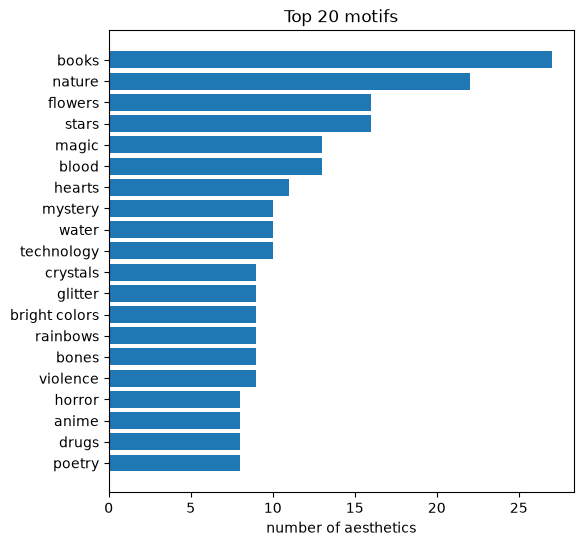

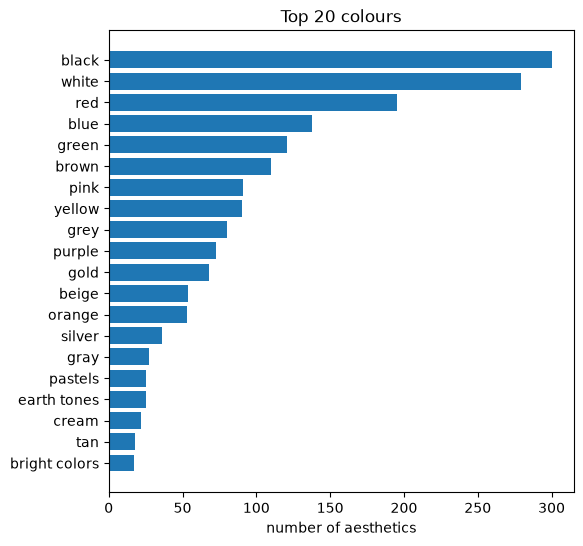

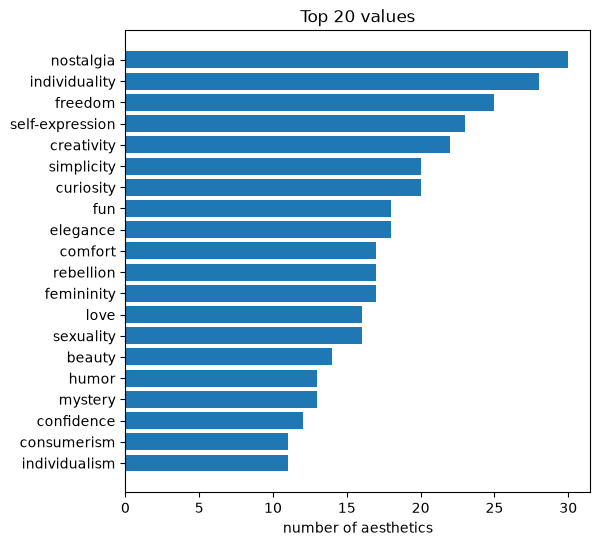

In [ ]:
all_motifs = []
all_colours = []
all_values = []

for i in range(len(hf_df)):
  for t in hf_df["motifs"][i].split(","):
    if t.strip() != "":
      all_motifs.append(t.strip())
  for t in hf_df["colours"][i].split(","):
    if t.strip() != "":
      all_colours.append(t.strip())
  for t in hf_df["values"][i].split(","):
    if t.strip() != "":
      all_values.append(t.strip())

motif_counts = pd.Series(all_motifs).value_counts()
colour_counts = pd.Series(all_colours).value_counts()
value_counts = pd.Series(all_values).value_counts()

print("unique motifs:", len(motif_counts), " colours:", len(colour_counts), " values:", len(value_counts))

for title, counts in [("motifs", motif_counts), ("colours", colour_counts), ("values", value_counts)]:
  top = counts.head(20)
  plt.figure(figsize=(6, 6))
  plt.barh(top.index[::-1], top.values[::-1])
  plt.title("Top 20 " + title)
  plt.xlabel("number of aesthetics")
  plt.show()

How many tags only show up once? (long tail = sparse data)

In [ ]:
for title, counts in [("motifs", motif_counts), ("colours", colour_counts), ("values", value_counts)]:
  print(title, "- used only once:", round((counts == 1).mean(), 2))

---
# 6. Getting it ready for models

| question | answer |
|---|---|
| DataFrame? Tensor? | DataFrame for the table. Text → TF-IDF → sparse matrix (rows = aesthetics, columns = words). Tensors come later in the neural net notebook. |
| Encoded? | yes, text → TF-IDF numbers. Era can stay as text, sklearn is fine with string labels. |
| Scaled? | no — TF-IDF already normalizes each row, and scaling would turn all the zeros into non-zeros. |
| Train / test? | saving the split now so the other notebooks use the same one. |

In [ ]:
tag_rows_df = hf_df[hf_df["tags_text"] != ""]

tag_vec = TfidfVectorizer(stop_words="english", min_df=5, max_df=0.5)
tag_vct = tag_vec.fit_transform(tag_rows_df["tags_text"])

lang_vec = TfidfVectorizer(stop_words="english", min_df=3, max_df=0.5)
lang_vct = lang_vec.fit_transform(hf_df["overview"])

print("tags:", tag_vct.shape)
print("overview:", lang_vct.shape)

tags: (943, 615)
overview: (1022, 1089)


Vaporwave's top TF-IDF words (what the computer "sees"):

In [ ]:
lang_vocab = lang_vec.get_feature_names_out()
vw_idx = list(hf_df["title"]).index("Vaporwave")

get_top_words(lang_vct[vw_idx], lang_vocab, n_words=10)

['clarity', 'styles', 'lack', 'despite', 'aesthetics']

Train / test split: only aesthetics with a known era, 80 / 20, saved as a `split` column.

In [ ]:
known_df = hf_df[hf_df["era"] != "unknown"]
train_df, test_df = train_test_split(known_df, test_size=0.2, random_state=1010)

train_titles = set(train_df["title"])
test_titles = set(test_df["title"])

splits = []
for t in hf_df["title"]:
  if t in train_titles:
    splits.append("train")
  elif t in test_titles:
    splits.append("test")
  else:
    splits.append("none")

hf_df["split"] = splits

hf_df["split"].value_counts()

split
train    556
none     327
test     139
Name: count, dtype: int64

---
# 7. SVD + t-SNE

PCA needs a normal (dense) table, so for sparse TF-IDF using `TruncatedSVD` instead

### How much do the first components keep?

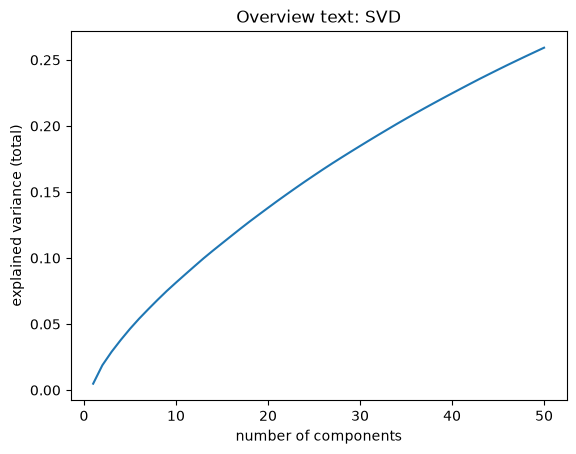

50 components keep: 0.259


In [ ]:
lang_svd = TruncatedSVD(n_components=50, random_state=1010)
lang_svd_feats = lang_svd.fit_transform(lang_vct)

# running total of explained variance
total = 0
running = []
for r in lang_svd.explained_variance_ratio_:
  total += r
  running.append(total)

plt.plot(range(1, 51), running)
plt.xlabel("number of components")
plt.ylabel("explained variance (total)")
plt.title("Overview text: SVD")
plt.show()

print("50 components keep:", round(sum(lang_svd.explained_variance_ratio_), 3))

### First 2 SVD components vs. t-SNE, colored by era

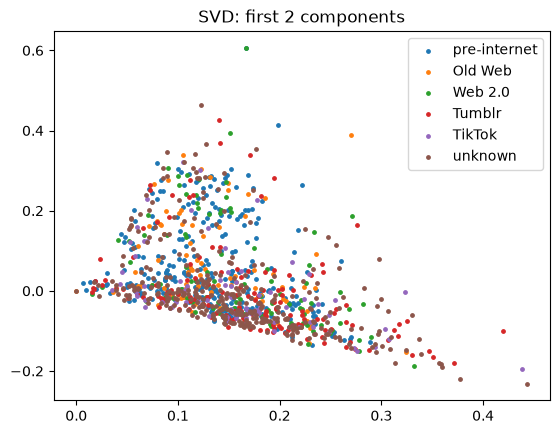

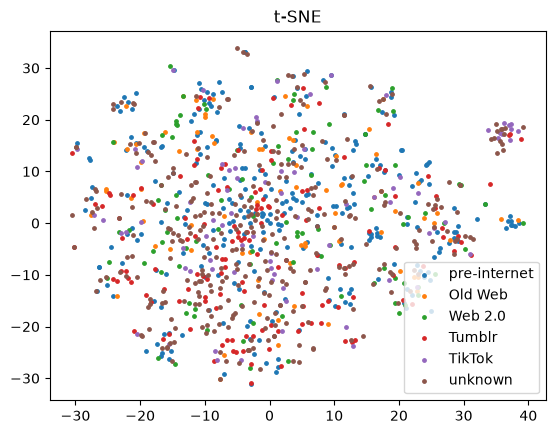

In [ ]:
lang_svd_df = pd.DataFrame(lang_svd_feats)

tsne = TSNE(n_components=2, random_state=1010).set_output(transform="pandas")
lang_tsne_df = tsne.fit_transform(lang_svd_feats)

for era in era_order:
  mask = (hf_df["era"] == era).values
  plt.scatter(lang_svd_df[0][mask], lang_svd_df[1][mask], s=6, label=era)
plt.title("SVD: first 2 components")
plt.legend()
plt.show()

for era in era_order:
  mask = (hf_df["era"] == era).values
  plt.scatter(lang_tsne_df["tsne0"][mask], lang_tsne_df["tsne1"][mask], s=6, label=era)
plt.title("t-SNE")
plt.legend()
plt.show()

Same thing for the tags:

50 components keep: 0.344


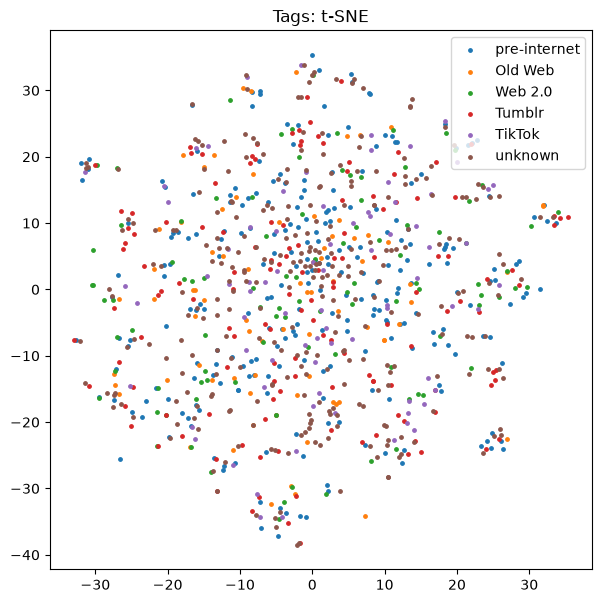

In [ ]:
tag_svd = TruncatedSVD(n_components=50, random_state=1010)
tag_svd_feats = tag_svd.fit_transform(tag_vct)
print("50 components keep:", round(sum(tag_svd.explained_variance_ratio_), 3))

tag_tsne_df = TSNE(n_components=2, random_state=1010).set_output(transform="pandas").fit_transform(tag_svd_feats)

plt.figure(figsize=(7, 7))
for era in era_order:
  mask = (tag_rows_df["era"] == era).values
  plt.scatter(tag_tsne_df["tsne0"][mask], tag_tsne_df["tsne1"][mask], s=6, label=era)
plt.title("Tags: t-SNE")
plt.legend()
plt.show()

---
# 8. Save

In [ ]:
hf_df["description"] = hf_df["description"].fillna("")

keep_cols = ["title", "decade", "decade_source", "era", "split", "motifs", "colours", "values",
             "tags_text", "n_tags", "overview", "overview_words", "description"]

hf_df[keep_cols].to_csv("data/clean/aesthetics_clean.csv", index=False)
print(hf_df[keep_cols].shape)

(1022, 13)
